# IAM Handwriting Writer Identification — Reproducible Comparison

This notebook creates **one deterministic 93-writer split** and evaluates every model against that exact split.

Models:
1. **LBP + SVM** classical baseline
2. **Grayscale ResNet18** pretrained transfer-learning baseline
3. **Grayscale ResNet18 + Dropout** regularized variant

## Fair-comparison protocol
- The split is generated once, then saved to `/kaggle/working/split_manifest.json`.
- Writers with fewer than 5 images are excluded; retained writer IDs are remapped to `0..92`.
- Each retained writer has samples in train, validation, and test.
- Model selection uses **validation macro F1**. The test set is evaluated only after selecting the checkpoint.
- All models use the same paths, labels, and test examples.
- Each neural model is initialized from the same pretrained ResNet18 weights where available. Random seeds are reset before each neural experiment.
- Results are saved separately and summarized at the end.

**Important limitation:** this is a small, closed-set writer-identification experiment, not a claim of matching an official IAM benchmark protocol. A writer may appear in all three splits by design; the images themselves must not overlap.


In [14]:
# 1. Environment, reproducibility, and paths
import os, sys, glob, tarfile, json, random, time, copy, hashlib, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

try:
    import torch
    import torch.nn as nn
    import torch.optim as optim
    from torch.utils.data import Dataset, DataLoader
    from torchvision import models
    from torchvision.models import ResNet18_Weights
    from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    from sklearn.svm import SVC
    import joblib
except ImportError as e:
    raise RuntimeError(f"Required package is missing: {e}") from e

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Expected Kaggle dataset locations; fall back to recursive discovery.
PROJECT_ROOT = "/kaggle/input/datasets/ayoubhammad/handwriting"
IAM_FORMS_PATH = "/kaggle/input/datasets/naderabdelghany/iam-handwritten-forms-dataset/data"
XML_ARCHIVE = "/kaggle/input/datasets/teykaicong/iamondb-handwriting-dataset/xml.tgz"
XML_DIR = "/kaggle/working/iam_xml"

def find_project_root():
    if os.path.isdir(os.path.join(PROJECT_ROOT, "src")):
        return PROJECT_ROOT
    candidates = glob.glob("/kaggle/input/**/src/utils/constants.py", recursive=True)
    if candidates:
        return str(Path(candidates[0]).parents[2])
    raise FileNotFoundError(
        "Could not find the WriterIdentifier source folder. Attach the "
        "ayoubhammad/handwriting Kaggle dataset and check its contents."
    )

PROJECT_ROOT = find_project_root()
SRC_DIR = os.path.join(PROJECT_ROOT, "src")
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

if not os.path.isdir(IAM_FORMS_PATH):
    candidates = glob.glob("/kaggle/input/**/iam-handwritten-forms-dataset/data", recursive=True)
    if candidates:
        IAM_FORMS_PATH = candidates[0]
    else:
        raise FileNotFoundError(f"IAM forms folder not found: {IAM_FORMS_PATH}")

if not os.path.isfile(XML_ARCHIVE):
    candidates = glob.glob("/kaggle/input/**/xml.tgz", recursive=True)
    if candidates:
        XML_ARCHIVE = candidates[0]
    else:
        raise FileNotFoundError(f"IAM XML archive not found: {XML_ARCHIVE}")

os.makedirs(XML_DIR, exist_ok=True)
if not any(Path(XML_DIR).rglob("*.xml")):
    print("Extracting XML annotations...")
    with tarfile.open(XML_ARCHIVE, "r:gz") as tar:
        # Avoid extracting absolute paths or path traversal entries.
        root_abs = os.path.abspath(XML_DIR)
        for member in tar.getmembers():
            target = os.path.abspath(os.path.join(XML_DIR, member.name))
            if target == root_abs or target.startswith(root_abs + os.sep):
                tar.extract(member, XML_DIR)

print("Project root:", PROJECT_ROOT)
print("IAM forms:", IAM_FORMS_PATH)
print("XML directory:", XML_DIR)


PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
Project root: /kaggle/input/datasets/ayoubhammad/handwriting
IAM forms: /kaggle/input/datasets/naderabdelghany/iam-handwritten-forms-dataset/data
XML directory: /kaggle/working/iam_xml


In [15]:
# 2. Load the source dataset, then create ONE fixed split
from utils import constants as C
from data.iam_dataset import IAMLoader

C.IAM_FORMS_PATH = IAM_FORMS_PATH
C.IAM_XML_PATH = XML_DIR
C.IAM_DATASET_ROOT = os.path.dirname(IAM_FORMS_PATH)

loader = IAMLoader(IAM_FORMS_PATH, XML_DIR).load()
source_splits = [loader.get_split(name) for name in ("train", "val", "test")]

# Recover the complete set of source examples. The subsequent deterministic
# split, not the original split assignment, is used for every model below.
all_paths, all_original_labels = [], []
for paths, labels in source_splits:
    all_paths.extend(list(paths))
    all_original_labels.extend([int(x) for x in labels])

# Deduplicate identical paths conservatively; inconsistent labels are an error.
path_to_label = {}
for p, y in zip(all_paths, all_original_labels):
    p = os.path.abspath(str(p))
    if p in path_to_label and path_to_label[p] != y:
        raise ValueError(f"One image path has conflicting writer labels: {p}")
    path_to_label[p] = y

all_paths = sorted(path_to_label)
all_original_labels = [path_to_label[p] for p in all_paths]

writer_to_paths = defaultdict(list)
for p, y in zip(all_paths, all_original_labels):
    writer_to_paths[y].append(p)

MIN_IMAGES_PER_WRITER = 5
eligible_writers = sorted(
    writer for writer, paths in writer_to_paths.items()
    if len(paths) >= MIN_IMAGES_PER_WRITER
)
if len(eligible_writers) < 2:
    raise RuntimeError("Too few eligible writers. Check dataset parsing.")

writer_to_new_label = {writer: i for i, writer in enumerate(eligible_writers)}
NUM_CLASSES = len(eligible_writers)

# Per-writer deterministic split. A local RNG seeded from global seed + writer ID
# makes the result stable regardless of dictionary iteration order.
train_paths, train_labels = [], []
val_paths, val_labels = [], []
test_paths, test_labels = [], []

for writer in eligible_writers:
    paths = sorted(writer_to_paths[writer])
    writer_seed = SEED + int(writer) * 1009
    rng = random.Random(writer_seed)
    rng.shuffle(paths)

    n = len(paths)
    n_test = max(1, int(round(n * 0.15)))
    n_val = max(1, int(round(n * 0.15)))

    # Keep at least one training example for every eligible writer.
    while n_test + n_val >= n:
        if n_val >= n_test and n_val > 1:
            n_val -= 1
        elif n_test > 1:
            n_test -= 1
        else:
            raise ValueError(f"Cannot split writer {writer}: only {n} images.")

    test_part = paths[:n_test]
    val_part = paths[n_test:n_test + n_val]
    train_part = paths[n_test + n_val:]
    label = writer_to_new_label[writer]

    train_paths.extend(train_part); train_labels.extend([label] * len(train_part))
    val_paths.extend(val_part); val_labels.extend([label] * len(val_part))
    test_paths.extend(test_part); test_labels.extend([label] * len(test_part))

# Stable ordering makes the manifest and metrics easier to audit.
def sort_split(paths, labels):
    pairs = sorted(zip(paths, labels), key=lambda item: (item[1], item[0]))
    return [p for p, _ in pairs], [int(y) for _, y in pairs]

train_paths, train_labels = sort_split(train_paths, train_labels)
val_paths, val_labels = sort_split(val_paths, val_labels)
test_paths, test_labels = sort_split(test_paths, test_labels)

# Validate class coverage, disjoint paths, and label mapping.
expected = set(range(NUM_CLASSES))
assert set(train_labels) == expected
assert set(val_labels) == expected
assert set(test_labels) == expected
assert len(set(train_paths) & set(val_paths)) == 0
assert len(set(train_paths) & set(test_paths)) == 0
assert len(set(val_paths) & set(test_paths)) == 0

split_manifest = {
    "seed": SEED,
    "min_images_per_writer": MIN_IMAGES_PER_WRITER,
    "num_classes": NUM_CLASSES,
    "writer_to_new_label": {str(k): int(v) for k, v in writer_to_new_label.items()},
    "train": [{"path": p, "label": int(y)} for p, y in zip(train_paths, train_labels)],
    "validation": [{"path": p, "label": int(y)} for p, y in zip(val_paths, val_labels)],
    "test": [{"path": p, "label": int(y)} for p, y in zip(test_paths, test_labels)],
}
os.makedirs("/kaggle/working/results", exist_ok=True)
with open("/kaggle/working/results/split_manifest.json", "w") as f:
    json.dump(split_manifest, f, indent=2)

print(f"Eligible writers: {NUM_CLASSES}")
print(f"Train: {len(train_paths)} images | {len(set(train_labels))} writers")
print(f"Val:   {len(val_paths)} images | {len(set(val_labels))} writers")
print(f"Test:  {len(test_paths)} images | {len(set(test_labels))} writers")
print("Path overlap train/val:", len(set(train_paths) & set(val_paths)))
print("Path overlap train/test:", len(set(train_paths) & set(test_paths)))
print("Path overlap val/test:", len(set(val_paths) & set(test_paths)))
print("Saved split manifest: /kaggle/working/results/split_manifest.json")

display(pd.DataFrame([
    {"split": "train", "images": len(train_paths), "writers": len(set(train_labels))},
    {"split": "validation", "images": len(val_paths), "writers": len(set(val_labels))},
    {"split": "test", "images": len(test_paths), "writers": len(set(test_labels))},
]))


[IAM] Writers after filtering (≥2 forms): 300 / 653
[IAM] Dataset split — train: 823, val: 178, test: 178 | 300 writers
Eligible writers: 93
Train: 441 images | 93 writers
Val:   113 images | 93 writers
Test:  113 images | 93 writers
Path overlap train/val: 0
Path overlap train/test: 0
Path overlap val/test: 0
Saved split manifest: /kaggle/working/results/split_manifest.json


,split,images,writers
0,train,441,93
1,validation,113,93
2,test,113,93


## 3. Shared dataset and evaluation helpers

The image paths and labels below are the single source of truth for all models. Training augmentation applies only to training images. Validation and test images are not augmented.


In [16]:
from data.writer_dataset import WriterDataset
from sklearn.metrics import classification_report, confusion_matrix
from skimage.feature import local_binary_pattern
import cv2

BATCH_SIZE = 16
NUM_WORKERS = 0  # robust on Kaggle

# Same source dataset/preprocessing for both neural models.
base_train = WriterDataset(train_paths, train_labels, augment=True)
base_val = WriterDataset(val_paths, val_labels, augment=False)
base_test = WriterDataset(test_paths, test_labels, augment=False)

class GrayscaleTensorDataset(Dataset):
    def __init__(self, base):
        self.base = base
    def __len__(self):
        return len(self.base)
    def __getitem__(self, idx):
        image, label = self.base[idx]
        image = image.float()
        label = torch.as_tensor(label, dtype=torch.long)
        if image.ndim != 3 or image.shape[0] != 1:
            raise ValueError(f"Expected [1,H,W] grayscale image, got {tuple(image.shape)}")
        return image, label

train_ds = GrayscaleTensorDataset(base_train)
val_ds = GrayscaleTensorDataset(base_val)
test_ds = GrayscaleTensorDataset(base_test)

def make_loaders(seed):
    generator = torch.Generator()
    generator.manual_seed(seed)
    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=generator,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
    )
    val_loader = DataLoader(
        val_ds, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
    )
    test_loader = DataLoader(
        test_ds, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
    )
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders(SEED)
images, labels = next(iter(train_loader))
print("Image batch:", tuple(images.shape), "| label dtype:", labels.dtype)
assert images.ndim == 4 and images.shape[1] == 1
assert labels.dtype == torch.long
del images, labels

def score_predictions(y_true, y_pred, num_classes=NUM_CLASSES):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(
            y_true, y_pred, labels=list(range(num_classes)),
            average="macro", zero_division=0
        )),
    }

results = {}
os.makedirs("/kaggle/working/checkpoints", exist_ok=True)
RESULTS_DIR = "/kaggle/working/results"
CHECKPOINT_DIR = "/kaggle/working/checkpoints"


Image batch: (16, 1, 128, 512) | label dtype: torch.int64


## 4. Model 1 — LBP + SVM baseline

This baseline uses the same training and test paths. The implementation computes features from each image path, so it does not use the neural-network dataset augmentation.


In [17]:
# Use the project's baseline implementation on the fixed split.
from models.lbp_svm import LBPSVMTrainer

lbp_trainer = LBPSVMTrainer(C=5.0, gamma="auto", seed=SEED)
t0 = time.time()
lbp_trainer.fit(train_paths, train_labels, verbose=True)
lbp_train_seconds = time.time() - t0

lbp_metrics = lbp_trainer.evaluate(test_paths, test_labels, verbose=True)
lbp_metrics["model"] = "LBP + SVM"
lbp_metrics["train_seconds"] = float(lbp_train_seconds)
lbp_metrics["num_classes"] = NUM_CLASSES
lbp_metrics["train_images"] = len(train_paths)
lbp_metrics["validation_images"] = len(val_paths)
lbp_metrics["test_images"] = len(test_paths)
lbp_metrics["split_seed"] = SEED

try:
    lbp_trainer.save()
except Exception as e:
    print("Model save warning:", repr(e))

with open(os.path.join(RESULTS_DIR, "lbp_svm_metrics.json"), "w") as f:
    json.dump({k: v for k, v in lbp_metrics.items()
               if isinstance(v, (str, int, float, bool, list, dict, type(None)))},
              f, indent=2)

results["LBP + SVM"] = {
    "accuracy": float(lbp_metrics.get("accuracy", 0.0)),
    "macro_f1": float(lbp_metrics.get("macro_f1", 0.0)),
    "train_seconds": float(lbp_train_seconds),
}
print("LBP + SVM summary:", results["LBP + SVM"])


[LBP+SVM] Extracting training features …
  [1/441] Processing a01-000u.png
  [51/441] Processing a06-124.png
  [101/441] Processing c03-096d.png
  [151/441] Processing e07-101.png
  [201/441] Processing g06-050c.png
  [251/441] Processing g06-031k.png
  [301/441] Processing g06-105.png
  [351/441] Processing j06-034.png
  [401/441] Processing n04-039.png
[LBP+SVM] Extracted 441 feature vectors (0 failed) in 435.9s
[LBP+SVM] Training SVM …
[LBP+SVM] SVM trained in 0.47s
[LBP+SVM] Extracting evaluation features …
  [1/113] Processing a01-053u.png
  [51/113] Processing f07-101b.png
  [101/113] Processing n04-044.png

[LBP+SVM] Accuracy : 0.9735
[LBP+SVM] Macro F1 : 0.9588
[LBP+SVM] Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         9
           1       1.00      1.00      1.00         1
           2       1.00      1.00      1.00         1
           3       1.00      1.00      1.00         1
           4      

## 5. Models 2 and 3 — ResNet18 variants

Both variants use the same grayscale input, split, number of epochs, optimizer schedule, and validation-based checkpoint selection. The intended difference is the classifier-head dropout setting: `0.0` versus `0.4`.

The training function restores the best checkpoint by validation macro F1 and evaluates the test split only once per trained model.


In [18]:
def build_resnet18(dropout_p, use_pretrained=True):
    pretrained_loaded = False
    if use_pretrained:
        try:
            net = models.resnet18(weights=ResNet18_Weights.DEFAULT)
            pretrained_loaded = True
        except Exception as exc:
            warnings.warn(f"Could not load pretrained weights ({exc!r}); using random initialization.")
            net = models.resnet18(weights=None)
    else:
        net = models.resnet18(weights=None)

    old_conv = net.conv1
    new_conv = nn.Conv2d(
        1, old_conv.out_channels, kernel_size=old_conv.kernel_size,
        stride=old_conv.stride, padding=old_conv.padding, bias=False
    )
    with torch.no_grad():
        if pretrained_loaded:
            new_conv.weight.copy_(old_conv.weight.mean(dim=1, keepdim=True))
        else:
            nn.init.kaiming_normal_(new_conv.weight, mode="fan_out", nonlinearity="relu")
    net.conv1 = new_conv

    in_features = net.fc.in_features
    if dropout_p > 0:
        net.fc = nn.Sequential(nn.Dropout(p=dropout_p), nn.Linear(in_features, NUM_CLASSES))
    else:
        net.fc = nn.Linear(in_features, NUM_CLASSES)
    return net.to(DEVICE), pretrained_loaded


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, y_true, y_pred = 0.0, [], []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += float(loss.item()) * labels.size(0)
        y_true.extend(labels.detach().cpu().tolist())
        y_pred.extend(logits.argmax(dim=1).detach().cpu().tolist())

    return (
        total_loss / max(len(loader.dataset), 1),
        score_predictions(y_true, y_pred)["accuracy"],
        score_predictions(y_true, y_pred)["macro_f1"],
        y_true, y_pred
    )


def train_resnet_variant(model_name, dropout_p, seed=SEED,
                         head_epochs=5, finetune_epochs=15):
    # Reset random state so the comparison is as controlled as possible.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    train_loader_local, val_loader_local, test_loader_local = make_loaders(seed)

    model, pretrained_loaded = build_resnet18(dropout_p=dropout_p, use_pretrained=True)
    criterion = nn.CrossEntropyLoss()
    checkpoint_path = os.path.join(CHECKPOINT_DIR, f"{model_name}_best.pth")
    metrics_path = os.path.join(RESULTS_DIR, f"{model_name}_metrics.json")
    best_val_f1, best_info = -1.0, {}
    history = []

    def phase(phase_name, epochs, optimizer, scheduler):
        nonlocal best_val_f1, best_info
        for epoch in range(1, epochs + 1):
            start = time.time()
            tr_loss, tr_acc, tr_f1, _, _ = run_epoch(
                model, train_loader_local, criterion, optimizer
            )
            va_loss, va_acc, va_f1, _, _ = run_epoch(
                model, val_loader_local, criterion
            )
            scheduler.step(va_f1)
            row = {
                "phase": phase_name, "epoch": epoch,
                "train_loss": tr_loss, "train_accuracy": tr_acc, "train_macro_f1": tr_f1,
                "val_loss": va_loss, "val_accuracy": va_acc, "val_macro_f1": va_f1,
                "seconds": time.time() - start
            }
            history.append(row)
            print(
                f"{model_name} | {phase_name} {epoch:02d}/{epochs} | "
                f"train acc={tr_acc:.4f} F1={tr_f1:.4f} | "
                f"val acc={va_acc:.4f} F1={va_f1:.4f} loss={va_loss:.4f} | "
                f"{row['seconds']:.1f}s"
            )
            if va_f1 > best_val_f1:
                best_val_f1 = float(va_f1)
                best_info = {"phase": phase_name, "epoch": epoch}
                torch.save({
                    "model_state_dict": copy.deepcopy(model.state_dict()),
                    "num_classes": NUM_CLASSES,
                    "dropout_p": dropout_p,
                    "best_validation_macro_f1": best_val_f1,
                    "phase": phase_name,
                    "epoch": epoch,
                    "seed": seed,
                    "pretrained_weights_loaded": pretrained_loaded,
                }, checkpoint_path)
                print("  Saved best validation checkpoint.")

    for p in model.parameters():
        p.requires_grad = False
    for p in model.fc.parameters():
        p.requires_grad = True

    optimizer = optim.AdamW(model.fc.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )
    phase("HEAD", head_epochs, optimizer, scheduler)

    for p in model.layer4.parameters():
        p.requires_grad = True
    for p in model.fc.parameters():
        p.requires_grad = True

    optimizer = optim.AdamW([
        {"params": model.layer4.parameters(), "lr": 1e-4},
        {"params": model.fc.parameters(), "lr": 1e-4},
    ], weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=3
    )
    phase("FINETUNE", finetune_epochs, optimizer, scheduler)

    checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint["model_state_dict"])
    test_loss, test_acc, test_f1, y_true, y_pred = run_epoch(
        model, test_loader_local, criterion
    )

    print(f"\n{model_name} final test accuracy: {test_acc:.4f}")
    print(f"{model_name} final test macro F1: {test_f1:.4f}")
    print(classification_report(
        y_true, y_pred, labels=list(range(NUM_CLASSES)),
        zero_division=0, digits=4
    ))

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    total_train_seconds = float(sum(r["seconds"] for r in history))
    metrics = {
        "model": model_name,
        "dropout_p": dropout_p,
        "pretrained_weights_loaded": pretrained_loaded,
        "num_classes": NUM_CLASSES,
        "train_images": len(train_ds),
        "validation_images": len(val_ds),
        "test_images": len(test_ds),
        "split_seed": SEED,
        "best_validation_macro_f1": float(best_val_f1),
        "best_phase": checkpoint["phase"],
        "best_epoch_within_phase": int(checkpoint["epoch"]),
        "test_loss": float(test_loss),
        "test_accuracy": float(test_acc),
        "test_macro_f1": float(test_f1),
        "train_seconds": total_train_seconds,
        "checkpoint": checkpoint_path,
        "confusion_matrix": cm.tolist(),
        "classification_report": classification_report(
            y_true, y_pred, labels=list(range(NUM_CLASSES)),
            zero_division=0, output_dict=True
        ),
        "history": history,
    }
    with open(metrics_path, "w") as f:
        json.dump(metrics, f, indent=2)

    results[model_name] = {
        "accuracy": float(test_acc),
        "macro_f1": float(test_f1),
        "best_validation_macro_f1": float(best_val_f1),
        "train_seconds": total_train_seconds,
    }
    print("Saved:", metrics_path)
    return model, metrics


# Model 2: no dropout in the classifier head.
resnet_model, resnet_metrics = train_resnet_variant(
    model_name="resnet18_grayscale",
    dropout_p=0.0
)

# Model 3: dropout in the classifier head.
dropout_model, dropout_metrics = train_resnet_variant(
    model_name="resnet18_grayscale_dropout",
    dropout_p=0.4
)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 173MB/s] 


resnet18_grayscale | HEAD 01/5 | train acc=0.0703 F1=0.0017 | val acc=0.0531 F1=0.0012 loss=4.6113 | 163.6s
  Saved best validation checkpoint.
resnet18_grayscale | HEAD 02/5 | train acc=0.0998 F1=0.0140 | val acc=0.0796 F1=0.0016 loss=4.3361 | 52.7s
  Saved best validation checkpoint.
resnet18_grayscale | HEAD 03/5 | train acc=0.1043 F1=0.0143 | val acc=0.1327 F1=0.0384 loss=3.9333 | 52.7s
  Saved best validation checkpoint.
resnet18_grayscale | HEAD 04/5 | train acc=0.1587 F1=0.0572 | val acc=0.1504 F1=0.0653 loss=3.4612 | 52.8s
  Saved best validation checkpoint.
resnet18_grayscale | HEAD 05/5 | train acc=0.2449 F1=0.1431 | val acc=0.2832 F1=0.1651 loss=3.1697 | 52.9s
  Saved best validation checkpoint.
resnet18_grayscale | FINETUNE 01/15 | train acc=0.4376 F1=0.3047 | val acc=0.4779 F1=0.3086 loss=2.2623 | 53.4s
  Saved best validation checkpoint.
resnet18_grayscale | FINETUNE 02/15 | train acc=0.7574 F1=0.6993 | val acc=0.6283 F1=0.4889 loss=1.7964 | 53.1s
  Saved best validation 

## 6. Final comparison and audit checks

Use the test metrics only for the final comparison. Validation macro F1 is included to show the model-selection signal, not as a substitute for test performance.


,model,test_accuracy,test_macro_f1,best_validation_macro_f1,train_seconds,num_classes,train_images,validation_images,test_images,split_seed
0,LBP + SVM,0.973451,0.958781,NaN,436.321306,93,441,113,113,42
2,resnet18_grayscale_dropout,0.805310,0.746953,0.880645,961.177412,93,441,113,113,42
1,resnet18_grayscale,0.805310,0.734861,0.855556,1171.928483,93,441,113,113,42


Comparison saved: /kaggle/working/results/model_comparison_same_split.csv


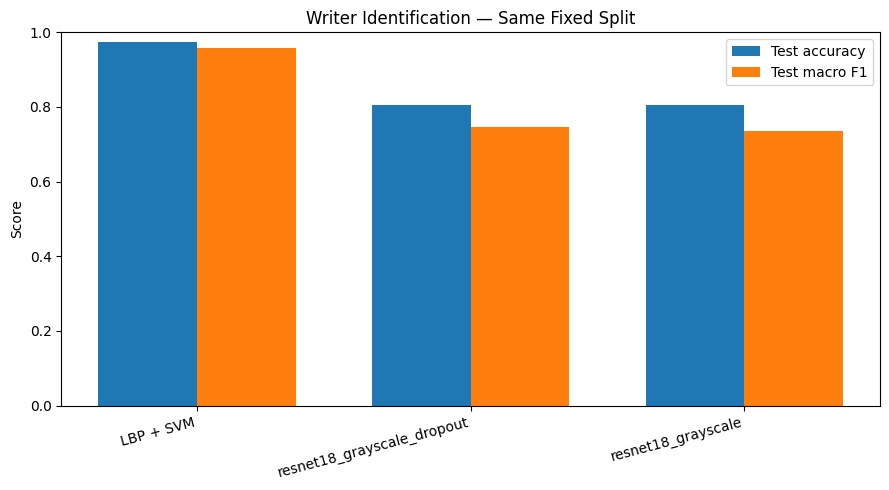


Reproducibility outputs:
- /kaggle/working/results/split_manifest.json
- /kaggle/working/results/experiment_audit.json
- /kaggle/working/results/model_comparison_same_split.csv
- /kaggle/working/results/model_comparison_same_split.png

Note: identical split does not eliminate uncertainty from the small test set.


In [19]:
comparison_rows = []
for name, values in results.items():
    comparison_rows.append({
        "model": name,
        "test_accuracy": values.get("accuracy"),
        "test_macro_f1": values.get("macro_f1"),
        "best_validation_macro_f1": values.get("best_validation_macro_f1", np.nan),
        "train_seconds": values.get("train_seconds", np.nan),
        "num_classes": NUM_CLASSES,
        "train_images": len(train_paths),
        "validation_images": len(val_paths),
        "test_images": len(test_paths),
        "split_seed": SEED,
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    "test_macro_f1", ascending=False
)
display(comparison_df)

comparison_csv = os.path.join(RESULTS_DIR, "model_comparison_same_split.csv")
comparison_df.to_csv(comparison_csv, index=False)
print("Comparison saved:", comparison_csv)

# Save a concise experiment index.
audit = {
    "seed": SEED,
    "num_classes": NUM_CLASSES,
    "train_images": len(train_paths),
    "validation_images": len(val_paths),
    "test_images": len(test_paths),
    "train_val_overlap": len(set(train_paths) & set(val_paths)),
    "train_test_overlap": len(set(train_paths) & set(test_paths)),
    "val_test_overlap": len(set(val_paths) & set(test_paths)),
    "split_manifest": "/kaggle/working/results/split_manifest.json",
    "comparison_csv": comparison_csv,
}
with open(os.path.join(RESULTS_DIR, "experiment_audit.json"), "w") as f:
    json.dump(audit, f, indent=2)

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(comparison_df))
width = 0.36
ax.bar(x - width/2, comparison_df["test_accuracy"], width, label="Test accuracy")
ax.bar(x + width/2, comparison_df["test_macro_f1"], width, label="Test macro F1")
ax.set_xticks(x)
ax.set_xticklabels(comparison_df["model"], rotation=15, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Writer Identification — Same Fixed Split")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "model_comparison_same_split.png"), dpi=160)
plt.show()

print("\nReproducibility outputs:")
print("- /kaggle/working/results/split_manifest.json")
print("- /kaggle/working/results/experiment_audit.json")
print("- /kaggle/working/results/model_comparison_same_split.csv")
print("- /kaggle/working/results/model_comparison_same_split.png")
print("\nNote: identical split does not eliminate uncertainty from the small test set.")
